# Intra-Khipu Structural Grammar (OKR v2.1.0)

Tests within-khipu relationships between color (`ascher_cord_color`), spatial cord grouping (`cord_cluster`), base-10 numeric values (`knot` + `knot_cluster`), and exact summation against within-khipu permutation and circular-shift nulls.

Set `RECOMPUTE = True` (with `KHIPU_DB_PATH` pointing to OKR v2.1.0 `khipu.db`) to recompute all `N_PERM = 1,000` tables from scratch; default `RECOMPUTE = False` loads the verified CSVs in `results/`.

In [1]:
import os, sys, pathlib
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import false_discovery_control
from IPython.display import Image, display

REPO_ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

RECOMPUTE = False   # Set True to re-run all permutations from khipu.db (~4 min total)
RESULTS = REPO_ROOT / 'results'
FIGURES = REPO_ROOT / 'figures'

if RECOMPUTE:
    from src import pilot_h1_h2, controls_h1_h2_h3, deep_dive_fdr_h3, extension_h5_sums, make_figures
    pilot_h1_h2.main()
    controls_h1_h2_h3.main()
    deep_dive_fdr_h3.main()
    extension_h5_sums.main()
    make_figures.fig1_fdr_and_controls()
    make_figures.fig2_h3_cooccurrence()
    make_figures.fig3_cataloger_invariance()
    make_figures.fig4_h5_sums_vs_null()

fdr_df = pd.read_csv(RESULTS / 'table_fdr_summary.csv')
dd_df  = pd.read_csv(RESULTS / 'deep_dive_fdr_1000.csv')
h5_df  = pd.read_csv(RESULTS / 'extension_h5_sums.csv')
print(f'Loaded {len(dd_df)} khipus (OKR v2.1.0, >=10 pendants).')

Loaded 512 khipus (OKR v2.1.0, >=10 pendants).


## 1. Within-Khipu Permutation & Circular-Shift Summary (BH-FDR $q < 0.05$)

,test,n,median,wilcoxon_p,raw_p05_pct,fdr_q05_n,fdr_q05_pct
0,"H1a NMI(cluster, color) [circular]",443,0.0164,1.750000e-19,26.0,0,0.0
1,H2a Color -> jump [circular],359,0.2163,2.720000e-10,17.0,0,0.0
2,H2b Cluster -> jump [circular],384,0.4188,1.600000e-26,23.2,0,0.0
3,Pure COLOR (inside cluster),318,0.1217,3.880000e-04,16.0,14,4.4
4,Pure CLUSTER (same color),148,0.3316,2.100000e-05,21.6,19,12.8
5,H3a Color positional homology,299,0.1132,4.890000e-33,48.5,133,44.5
6,H3b Numeric R^2 positional homology,326,0.1280,2.880000e-35,48.8,133,40.8


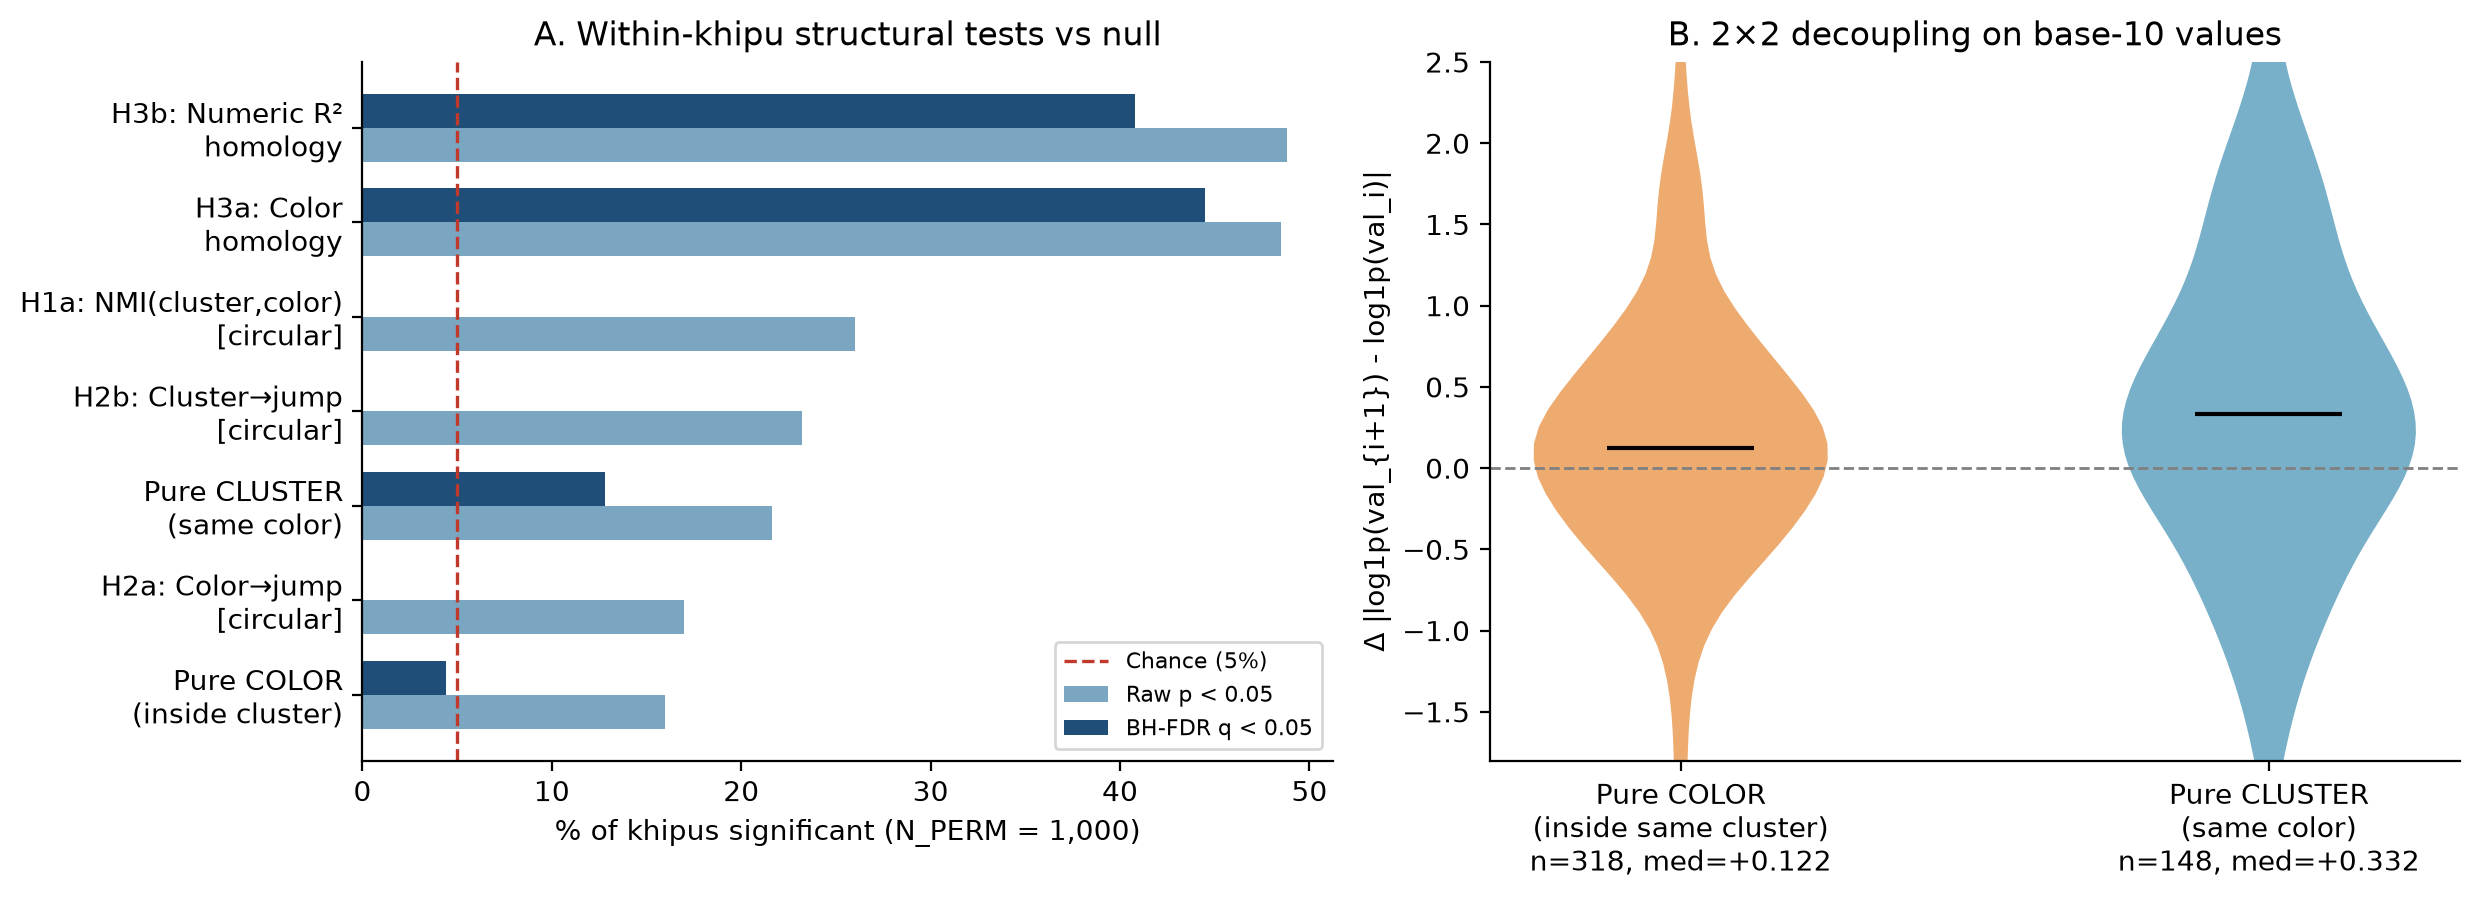

In [2]:
display(fdr_df)
display(Image(filename=str(FIGURES / 'fig1_intra_khipu_summary.png'), width=850))

## 2. H3 Co-Occurrence (Color & Numeric Positional Homology) & Clean-Decimal Sensitivity

H3b_numeric_FDR,False,True
H3a_color_FDR,,
False,119,39
True,41,86


Fisher exact: OR = 6.40, p = 2.66e-13 | Spearman rho = 0.375 (p = 6.39e-11)


,OKR_NUM,cataloger,museum,h3_G,h3_m,h3_col_match,h3_val_r2,clean_dec_frac
359,KH0411,UR,"American Museum of Natural History, NY",7,4,1.000,0.875,1.000
79,KH0151,UR,"Museum für Völkerkunde, Berlin",2,8,1.000,0.833,1.000
260,KH0261,UR,"Museum Fur Volkerkunde, Munich, W. Germany",4,7,0.929,0.903,0.978
56,KH0128,UR,"Museum für Völkerkunde, Berlin",2,160,0.875,0.944,0.979
72,KH0144,AS,"Museum für Völkerkunde, Berlin",2,7,1.000,0.745,1.000
243,KH0101,UR,"Museum Fur Volkerkunde, Munich, W. Germany",12,4,0.833,0.909,1.000
208,KH0286,UR,Banco Central de la Reserva,2,36,0.806,0.925,1.000
325,KH0544,HP,Museo de Sitio de Pachacamac,6,6,0.822,0.904,1.000
14,KH0224,AS,"Museum of Culture History, University of Calif...",4,6,1.000,0.724,1.000
480,KH0511,UR,Proyecto Incahuasi,7,3,0.746,0.973,0.842


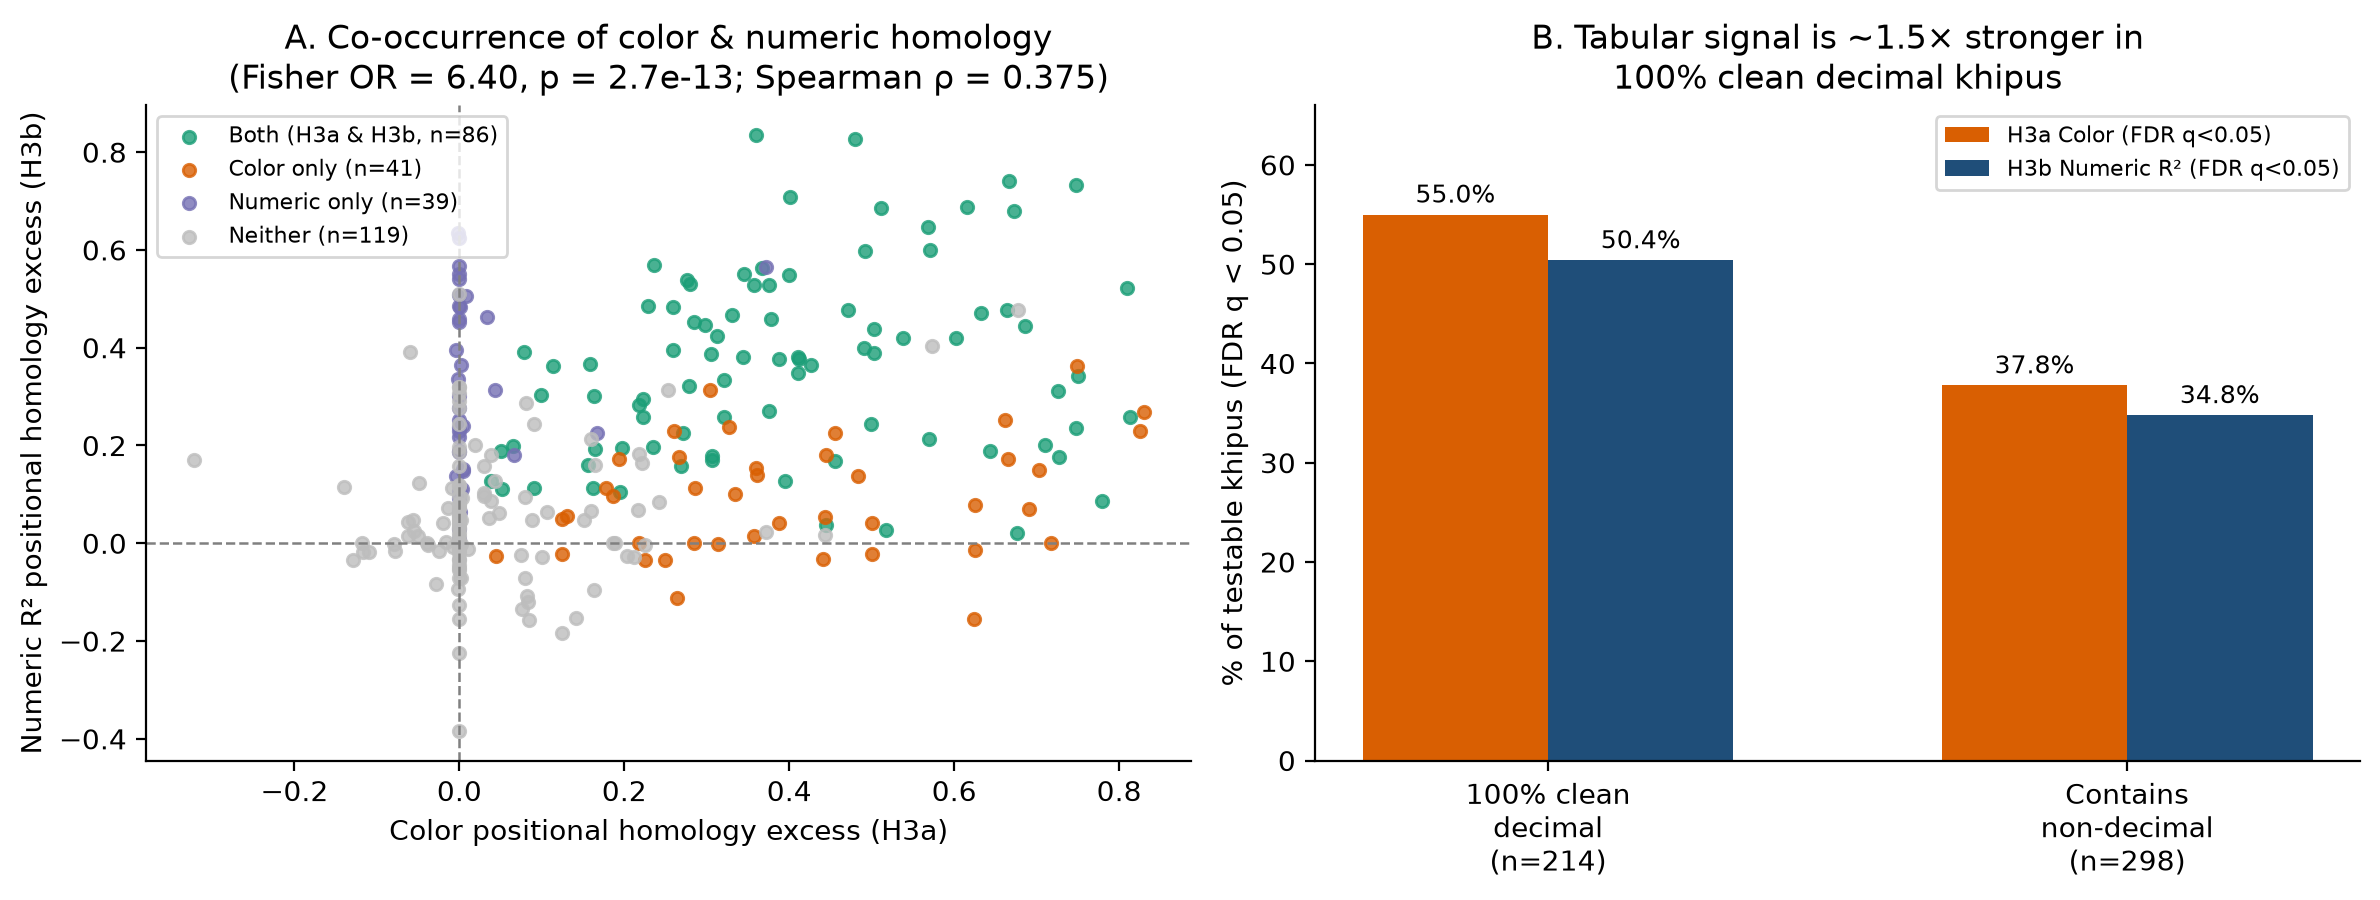

In [3]:
both = dd_df.dropna(subset=['h3_col_p', 'h3_val_p']).copy()
both['q_col'] = false_discovery_control(both['h3_col_p'].values, method='bh')
both['q_val'] = false_discovery_control(both['h3_val_p'].values, method='bh')
ct = pd.crosstab(both['q_col'] < 0.05, both['q_val'] < 0.05, rownames=['H3a_color_FDR'], colnames=['H3b_numeric_FDR'])
or_val, p_fish = stats.fisher_exact(ct)
rho, p_rho = stats.spearmanr(both['h3_col_exc'], both['h3_val_exc'])
display(ct)
print(f'Fisher exact: OR = {or_val:.2f}, p = {p_fish:.2e} | Spearman rho = {rho:.3f} (p = {p_rho:.2e})')

top10 = both[(both['q_col'] < 0.05) & (both['q_val'] < 0.05)].assign(
    score=lambda d: d['h3_val_r2'] + d['h3_col_match']
).sort_values('score', ascending=False).head(10)
display(top10[['OKR_NUM', 'cataloger', 'museum', 'h3_G', 'h3_m', 'h3_col_match', 'h3_val_r2', 'clean_dec_frac']].round(3))
display(Image(filename=str(FIGURES / 'fig2_h3_cooccurrence_tabular.png'), width=850))

## 3. H4 Cataloger & Museum Invariance

,n,h1_circ_pct,h3a_col_pct,h3b_val_pct,pure_cl_med
cataloger,,,,,
AS,111,26.3,50.0,46.7,0.279
HP,48,20.9,61.3,29.0,0.481
JC,14,0.0,28.6,42.9,0.636
QU,11,25.0,100.0,100.0,0.146
UR,327,27.8,46.2,52.4,0.319


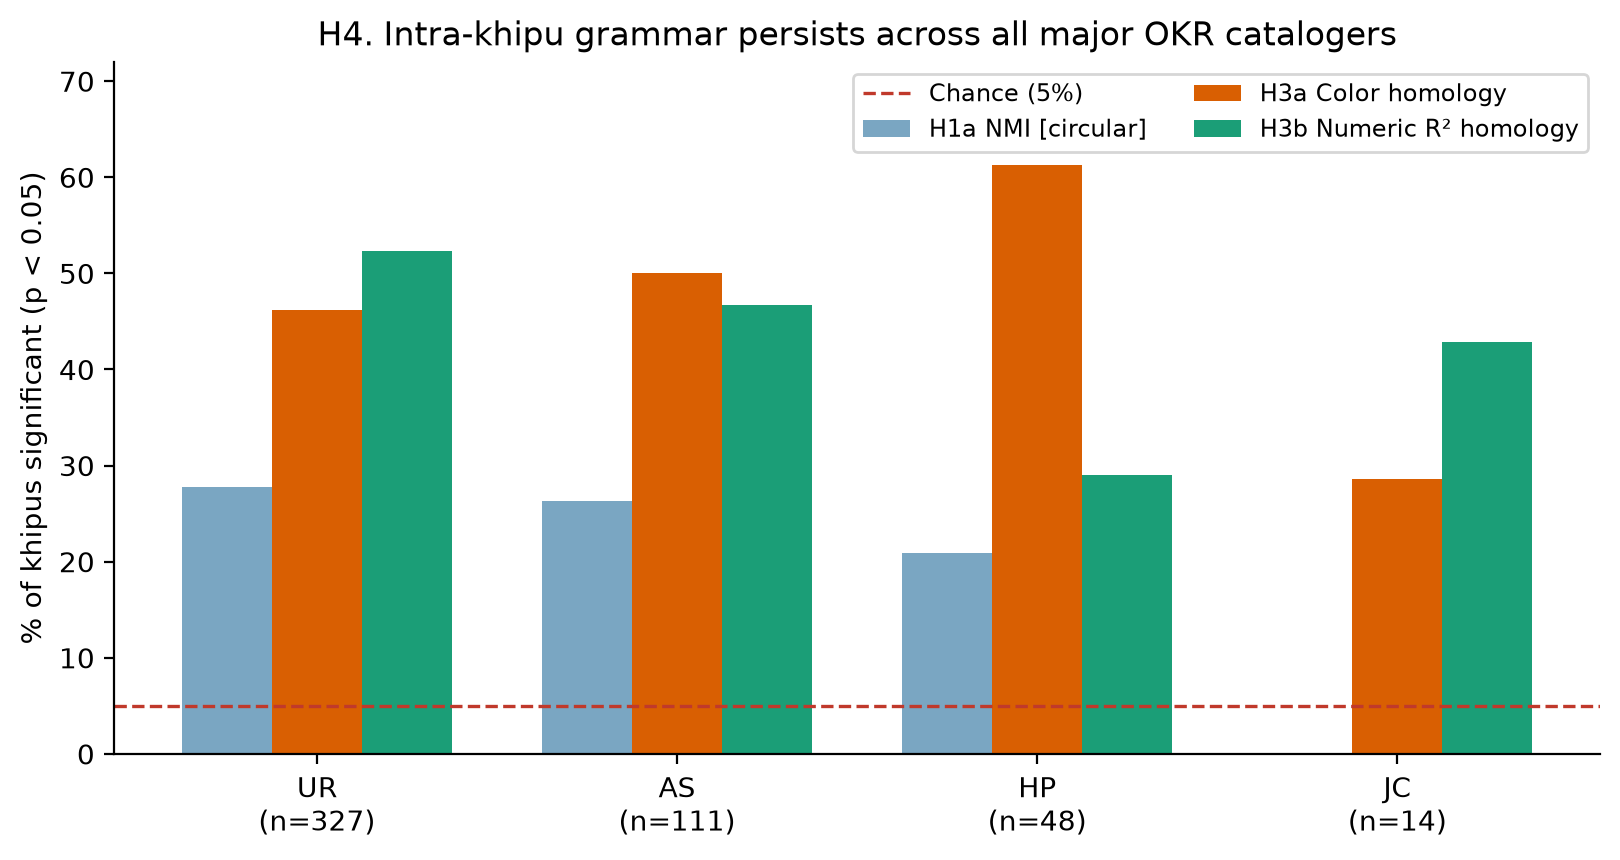

In [4]:
top_cats = dd_df['cataloger'].value_counts()
top_cats = top_cats[top_cats >= 10].index.tolist()
inv_cat = dd_df[dd_df['cataloger'].isin(top_cats)].groupby('cataloger').agg(
    n=('KHIPU_ID', 'count'),
    h1_circ_pct=('h1_p_circ', lambda x: round(100 * (x.dropna() < 0.05).mean(), 1)),
    h3a_col_pct=('h3_col_p', lambda x: round(100 * (x.dropna() < 0.05).mean(), 1)),
    h3b_val_pct=('h3_val_p', lambda x: round(100 * (x.dropna() < 0.05).mean(), 1)),
    pure_cl_med=('pure_cl_diff', 'median'),
).round(3)
display(inv_cat)
display(Image(filename=str(FIGURES / 'fig3_cataloger_invariance.png'), width=700))

## 4. H5 Null-Calibrated Within-Khipu Exact Sums (`N_PERM = 500`)

,Test,n,Obs_hits,Null_expected,Ratio,Khipus_p05
0,H5b: Within-cluster first/last subtotal,494,36,35.4,1.02,0
1,H5c: Cross-group first/last slot sum,244,32,17.8,1.80,6
2,H5c: Cross-group any-row slot sum,244,43,33.6,1.28,7


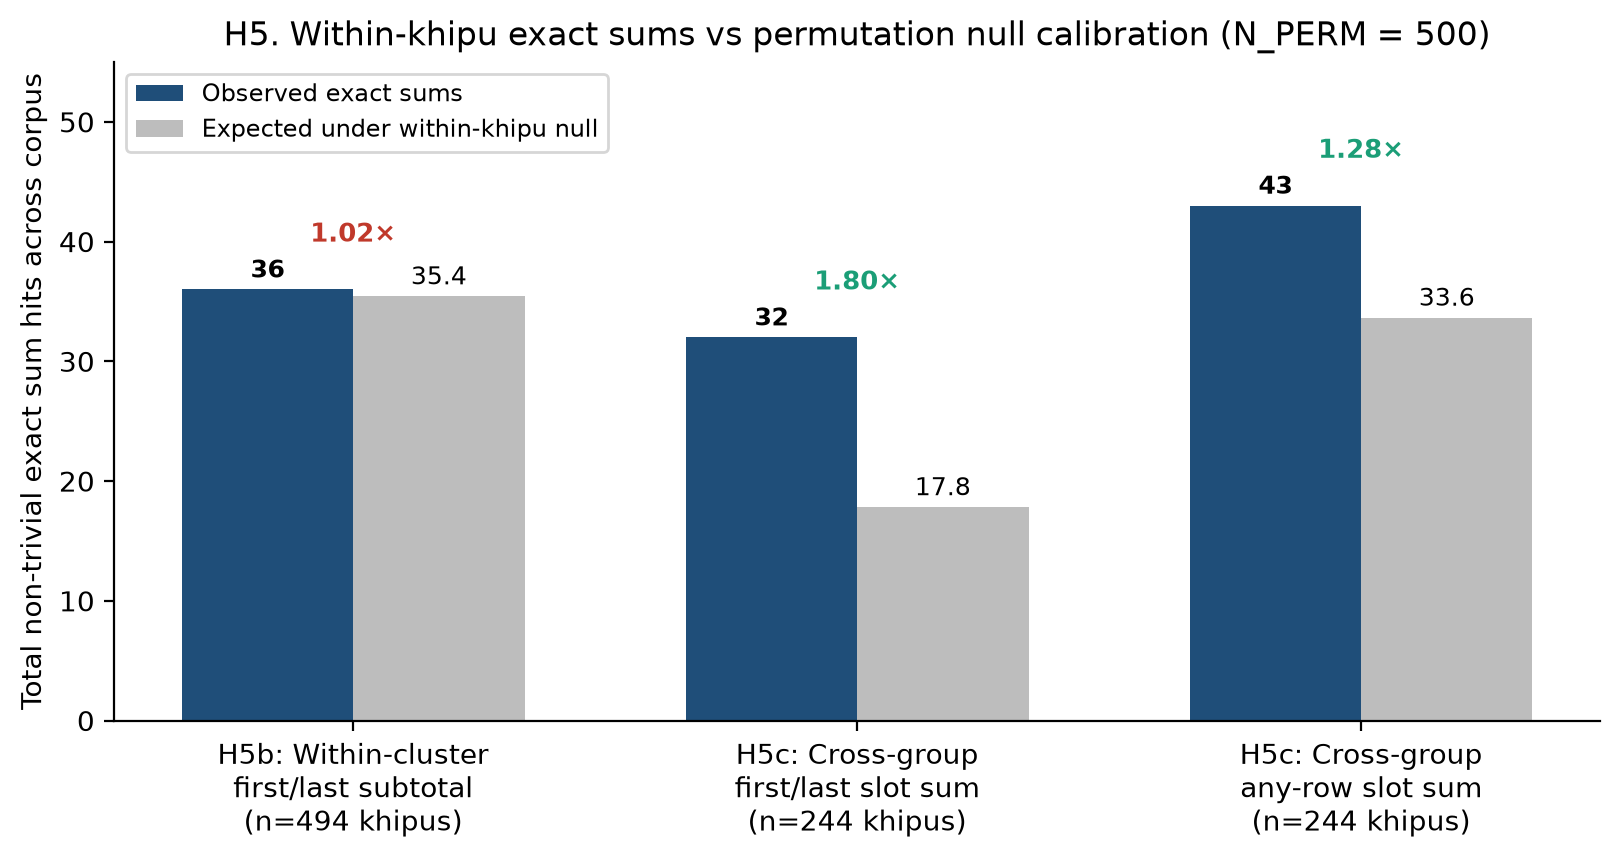

In [5]:
b = h5_df.dropna(subset=['h5b_hits'])
c = h5_df.dropna(subset=['h5c_hits'])
sum_tbl = pd.DataFrame([
    {'Test': 'H5b: Within-cluster first/last subtotal', 'n': len(b), 'Obs_hits': int(b['h5b_hits'].sum()),
     'Null_expected': round(float(b['h5b_null'].sum()), 1), 'Ratio': round(float(b['h5b_hits'].sum() / b['h5b_null'].sum()), 2),
     'Khipus_p05': int((b['h5b_p'] < 0.05).sum())},
    {'Test': 'H5c: Cross-group first/last slot sum', 'n': len(c), 'Obs_hits': int(c['h5c_hits'].sum()),
     'Null_expected': round(float(c['h5c_null'].sum()), 1), 'Ratio': round(float(c['h5c_hits'].sum() / c['h5c_null'].sum()), 2),
     'Khipus_p05': int((c['h5c_p'] < 0.05).sum())},
    {'Test': 'H5c: Cross-group any-row slot sum', 'n': len(c), 'Obs_hits': int(c['h5c_any_hits'].sum()),
     'Null_expected': round(float(c['h5c_any_null'].sum()), 1), 'Ratio': round(float(c['h5c_any_hits'].sum() / c['h5c_any_null'].sum()), 2),
     'Khipus_p05': int((c['h5c_any_p'] < 0.05).sum())},
])
display(sum_tbl)
display(Image(filename=str(FIGURES / 'fig4_h5_sums_vs_null.png'), width=700))